# 02 — Pan-human Azimuth vs lab ground-truth labels

Requires `01_run_azimuth` to have written `results/pha_<dataset>_predictions.csv`.

PHA and the lab use different label vocabularies, so both are compared in **Cell Ontology (CL)** space:
- truth: `label_crosswalk.csv` maps each lab label to the most specific CL term it justifies
- prediction: PHA's own crosswalk (`final_level_labels_CL_ID`)

Each cell is scored by how the predicted CL term relates to the true one in the CL is_a hierarchy:

| outcome | meaning | example (truth → PHA) |
|---|---|---|
| `exact` | same CL term | hepatocyte → Hepatocyte |
| `finer` | PHA is a descendant of the truth (correct, more specific) | macrophage → LYVE1 macrophage |
| `coarser` | PHA is an ancestor of the truth (correct, less specific) | protoplasmic astrocyte → Astrocyte |
| `wrong` | neither | follicular dendritic cell → Alveolar macrophage |
| `unassigned` | PHA QC label (empty droplet / ambient / doublet-like) | |

**correct** = exact + finer + coarser. Glioma malignant states (AC/MES/NPC/OPC-like) have no healthy
counterpart in PHA's reference, so they are excluded from scores and shown separately.

In [1]:
import os, sys
from pathlib import Path

# Run from the repo root (found via config.py) so relative paths are stable
_root = Path.cwd()
while not (_root / "config.py").exists():
    _root = _root.parent
os.chdir(_root)
sys.path.insert(0, str(_root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config import DATASETS, RESULTS_DIR, C2S_ROOT
from cl_utils import CellOntology

cl = CellOntology(C2S_ROOT / "ontology" / "cl-basic.obo")
crosswalk = pd.read_csv("label_crosswalk.csv")
EVAL_DIR = RESULTS_DIR / "eval_vs_truth"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

RELATION_TO_OUTCOME = {"exact": "exact", "descendant": "finer", "ancestor": "coarser",
                       "wrong": "wrong", "none": "unassigned"}
OUTCOMES = ["exact", "finer", "coarser", "wrong", "unassigned"]

## 1. Score every cell

In [3]:
def score_dataset(name):
    m = pd.read_csv(RESULTS_DIR / f"pha_{name}_predictions.csv", index_col=0)
    cw = crosswalk[crosswalk["dataset"] == name].set_index("raw_label")
    missing = set(m["true_label"]) - set(cw.index)
    assert not missing, f"{name}: labels missing from label_crosswalk.csv: {missing}"

    df = pd.DataFrame(index=m.index)
    df["dataset"] = name
    df["true_label"] = m["true_label"]
    df["true_cl_id"] = m["true_label"].map(cw["cl_id"])
    df["true_cl_name"] = m["true_label"].map(cw["cl_name"])
    df["scorable"] = m["true_label"].map(cw["scorable"]).astype(bool)
    df["pha_label"] = m["final_level_labels"]
    df["pha_cl_id"] = m["final_level_labels_CL_ID"].where(m["final_level_labels_CL_ID"] != "unmapped")
    df["pha_conf"] = m["final_level_confidence"]
    df["pha_consistent"] = m["full_consistent_hierarchy"]
    df["outcome"] = [RELATION_TO_OUTCOME[cl.relation(p if isinstance(p, str) else None, t)]
                     for p, t in zip(df["pha_cl_id"], df["true_cl_id"])]
    df["correct"] = df["outcome"].isin(["exact", "finer", "coarser"])
    df["lca_hops"] = [cl.lca_hops(p, t) if isinstance(p, str) else np.nan
                      for p, t in zip(df["pha_cl_id"], df["true_cl_id"])]
    return df

cells = pd.concat([score_dataset(n) for n in DATASETS])
cells.to_csv(EVAL_DIR / "per_cell.csv")
scored = cells[cells["scorable"]]
print(f"{len(cells):,} cells | {len(scored):,} scorable | "
      f"{(~cells['scorable']).sum():,} excluded (glioma malignant states)")

23,936 cells | 23,136 scorable | 800 excluded (glioma malignant states)


## 2. Per-dataset summary
`macro_correct` averages per-class correct rates, so large classes don't dominate.

In [4]:
def summarize(df):
    out = df["outcome"].value_counts(normalize=True).reindex(OUTCOMES, fill_value=0) * 100
    per_class = df.groupby("true_label")["correct"].mean() * 100
    return pd.Series({
        "n_cells": len(df),
        "n_classes": df["true_label"].nunique(),
        **{f"{o}_%": out[o] for o in OUTCOMES},
        "correct_%": df["correct"].mean() * 100,
        "macro_correct_%": per_class.mean(),
        "median_lca_hops": df["lca_hops"].median(),
        "median_conf": df["pha_conf"].median(),
    })

summary = scored.groupby("dataset", sort=False).apply(summarize)
summary.loc["ALL"] = summarize(scored)
summary.round(1).to_csv(EVAL_DIR / "summary.csv")
summary.round(1)

/tmp/ipykernel_254405/46837770.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = scored.groupby("dataset", sort=False).apply(summarize)


,n_cells,n_classes,exact_%,finer_%,coarser_%,wrong_%,unassigned_%,correct_%,macro_correct_%,median_lca_hops,median_conf
dataset,,,,,,,,,,,
glioma,1809.0,10.0,41.4,32.8,6.6,19.2,0.0,80.8,76.3,1.0,0.9
Brain_normal,2773.0,15.0,59.1,18.9,8.8,12.3,0.9,86.8,77.5,0.0,1.0
Liver_normal,2806.0,11.0,37.3,0.7,23.2,38.7,0.0,61.3,62.8,1.0,1.0
Lymph_node_normal,2357.0,11.0,42.5,36.0,0.6,21.0,0.0,79.0,69.2,1.0,0.9
lymphoid,7173.0,11.0,31.3,17.3,15.3,36.1,0.1,63.9,57.9,2.0,0.9
myeloid,6218.0,15.0,53.7,18.9,4.3,23.1,0.0,76.9,64.4,0.0,1.0
ALL,23136.0,65.0,43.3,19.0,10.4,27.2,0.1,72.7,68.2,1.0,1.0


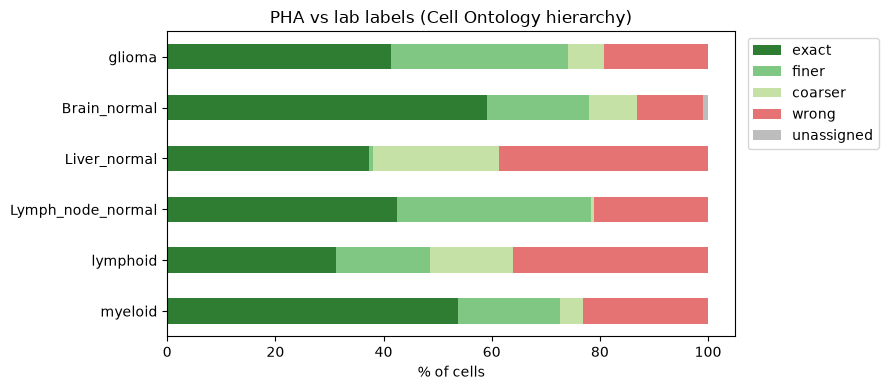

In [5]:
ax = summary.drop("ALL")[[f"{o}_%" for o in OUTCOMES]].plot(
    kind="barh", stacked=True, figsize=(9, 4),
    color=["#2e7d32", "#81c784", "#c5e1a5", "#e57373", "#bdbdbd"])
ax.set_xlabel("% of cells"); ax.set_ylabel(""); ax.invert_yaxis()
ax.legend([o for o in OUTCOMES], bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("PHA vs lab labels (Cell Ontology hierarchy)")
plt.tight_layout(); plt.savefig(EVAL_DIR / "outcomes_by_dataset.png", dpi=150); plt.show()

## 3. Per-class breakdown
For each lab label: how often PHA is correct, and what it most often predicts.

In [6]:
def top_preds(s, k=3):
    vc = s.value_counts(normalize=True).head(k) * 100
    return ", ".join(f"{lbl} ({pct:.0f}%)" for lbl, pct in vc.items())

per_class = (scored.groupby(["dataset", "true_label"], sort=False)
             .agg(n=("outcome", "size"),
                  true_cl=("true_cl_name", "first"),
                  correct_pct=("correct", lambda s: 100 * s.mean()),
                  exact_pct=("outcome", lambda s: 100 * (s == "exact").mean()),
                  wrong_pct=("outcome", lambda s: 100 * (s == "wrong").mean()),
                  top_pha_predictions=("pha_label", top_preds))
             .round(1))
per_class.to_csv(EVAL_DIR / "per_class.csv")
pd.set_option("display.max_colwidth", 90, "display.max_rows", 200)
per_class

n  \
dataset           true_label                                             
glioma            CD4/CD8                                          200   
                  Pericyte                                         200   
                  Endothelial                                      200   
                  TAM-MG                                           200   
                  TAM-BDM                                          200   
                  Oligodendrocyte                                  200   
                  DC                                                 9   
                  OPC                                              200   
                  Astrocyte                                        200   
                  Neuron                                           200   
Brain_normal      astrocyte_fibrous_like                           146   
                  neuron                                           609   
                  smooth_muscle_cell                                21   
                  oligodendrocyte                                  822   
                  GABAergic_interneuron_SST                         55   
                  meningeal_fibroblast                              22   
                  venous_endothelial_cell                           43   
                  astrocyte_protoplasmic                           267   
                  perivascular_fibroblast                           51   
                  oligodendrocyte_precursor_cell                    86   
                  GABAergic_interneuron                            153   
                  capillary_endothelial_cell                       164   
                  arterial_endothelial_cell                        107   
                  pericyte                                         104   
                  oligodendrocyte_ISG_expressing                   123   
Liver_normal      hepatic_stellate_cell_ACTA2_high                 201   
                  hepatocyte                                       911   
                  hepatic_stellate_cell_HGF_high                   386   
                  cholangiocyte                                    152   
                  hepatic_stellate_cell_ACTA2_high_collagen_high    93   
                  pericyte                                          88   
                  liver_pericentral_capillary_endothelial_cell     672   
                  liver_periportal_capillary_endothelial_cell      192   
                  venous_endothelial_cell                           45   
                  endothelial_cell_proliferating                    27   
                  arterial_endothelial_cell                         39   
Lymph_node_normal follicular_dendritic_cell                        264   
                  venous_endothelial_cell                          167   
                  LN_fibroblast_collagen_high                      539   
                  pericyte                                          87   
                  arterial_endothelial_cell                         57   
                  lymphatic_endothelial_cell                        93   
                  capillary_endothelial_cell                       209   
                  LN_stroma_cell                                   664   
                  LN_stroma_cell_CHI3L1                            204   
                  smooth_muscle_cell                                50   
                  adipocyte                                         23   
lymphoid          plasma_cell_proliferating                        234   
                  CD4_T_cell_activated                             532   
                  plasma_cell                                     1476   
                  B_cell                                           990   
                  CD8_T_cell_early_activated                      1040   
                  Treg_cell                                        391   

## 4. Confusion heatmaps (lab label × PHA label, row-normalized)
Columns are PHA's top predicted labels per dataset; the rest are pooled into "other".

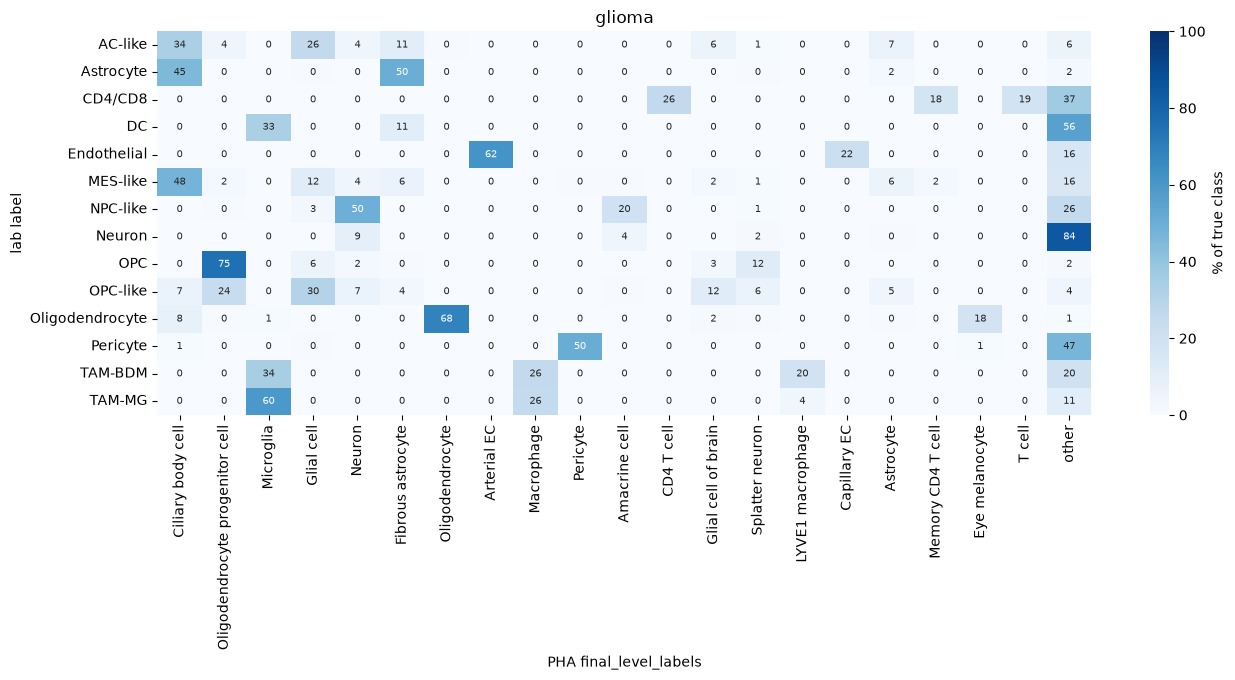

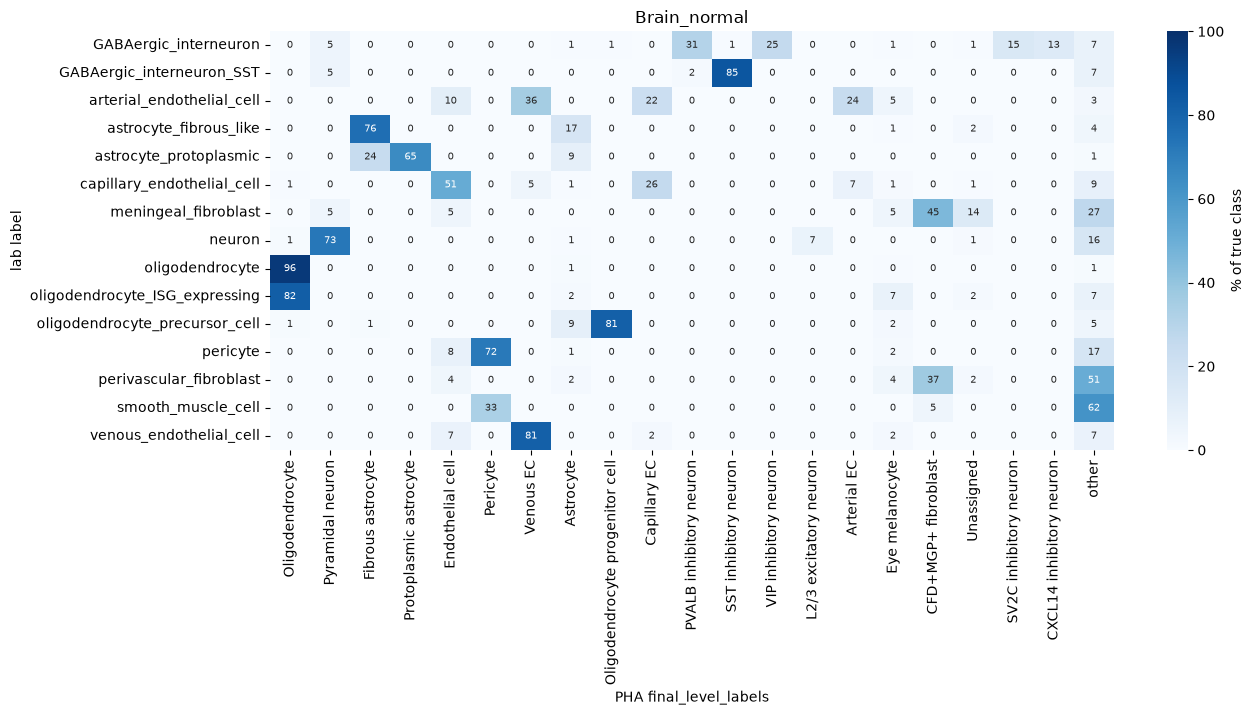

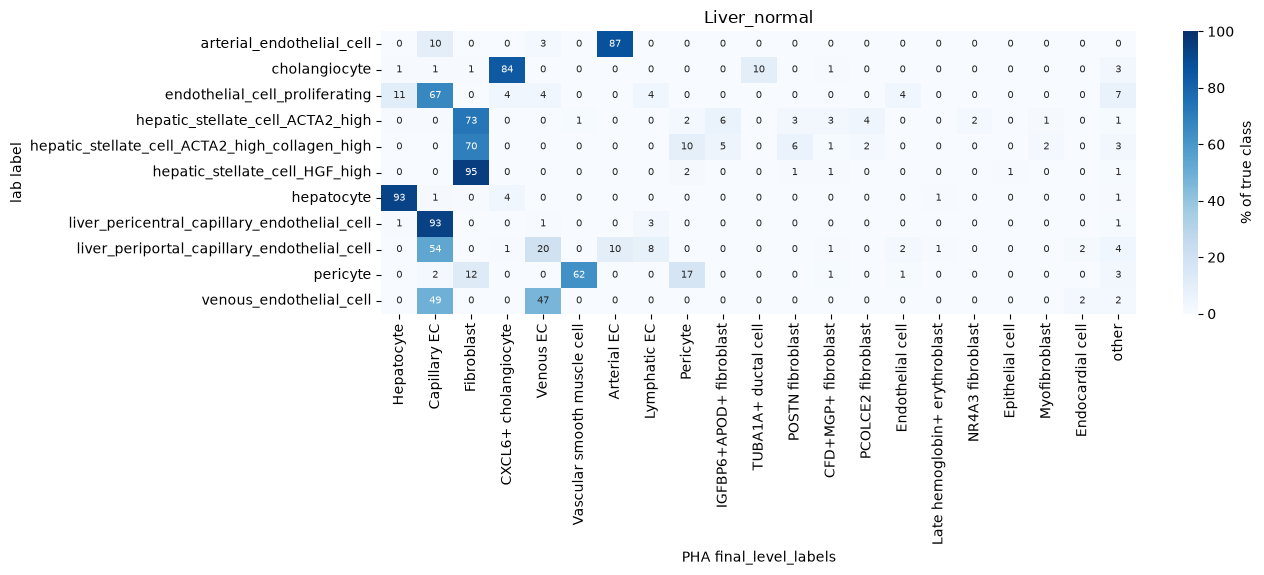

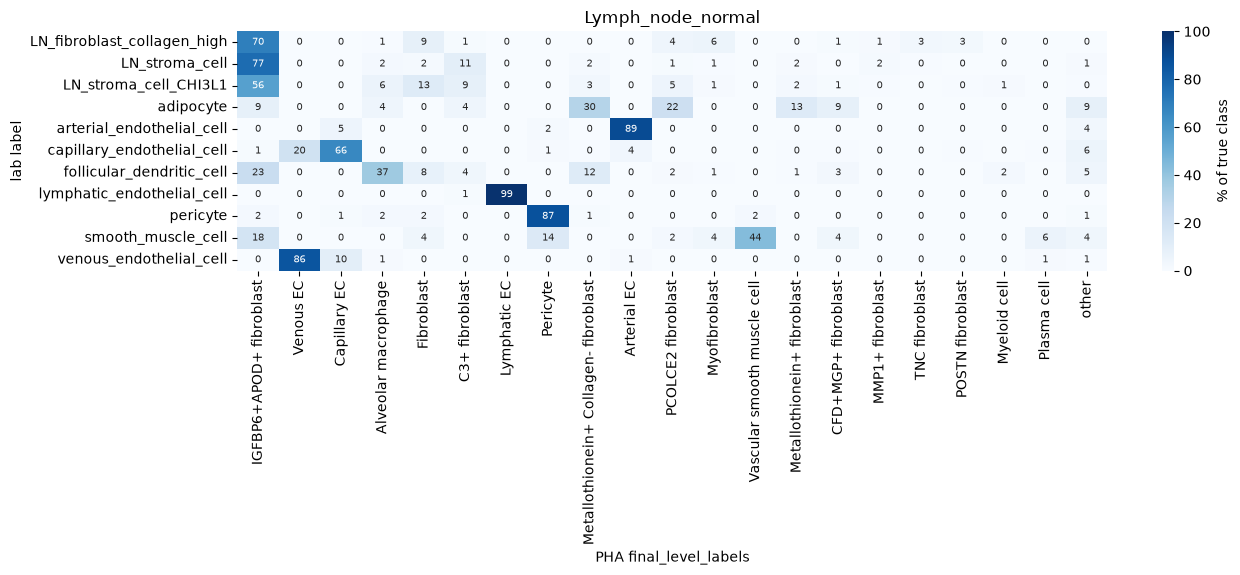

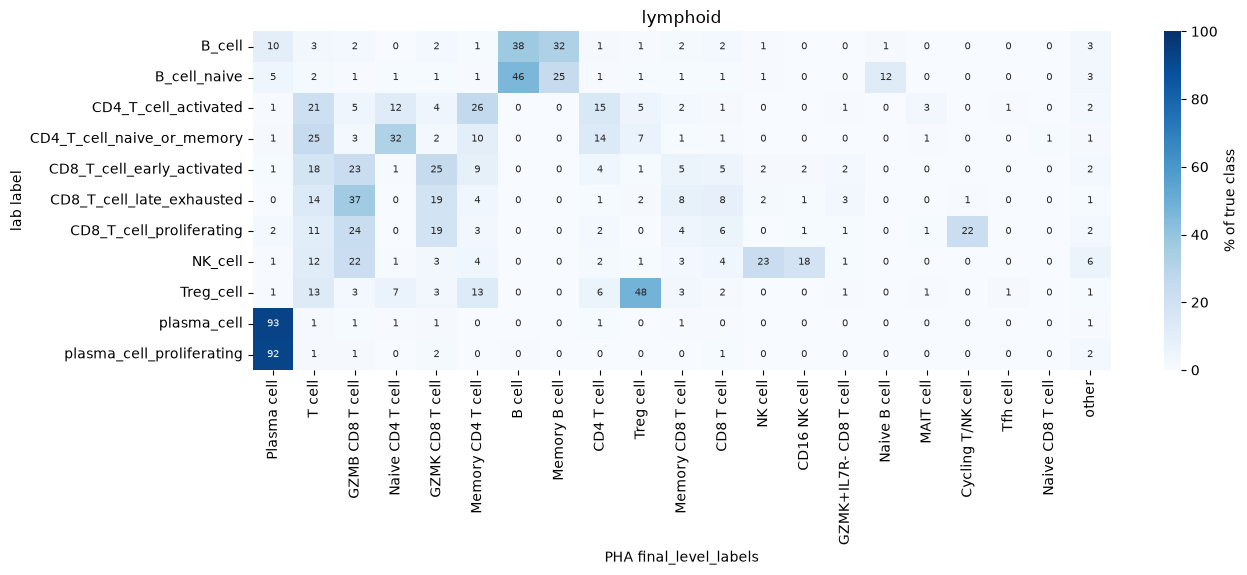

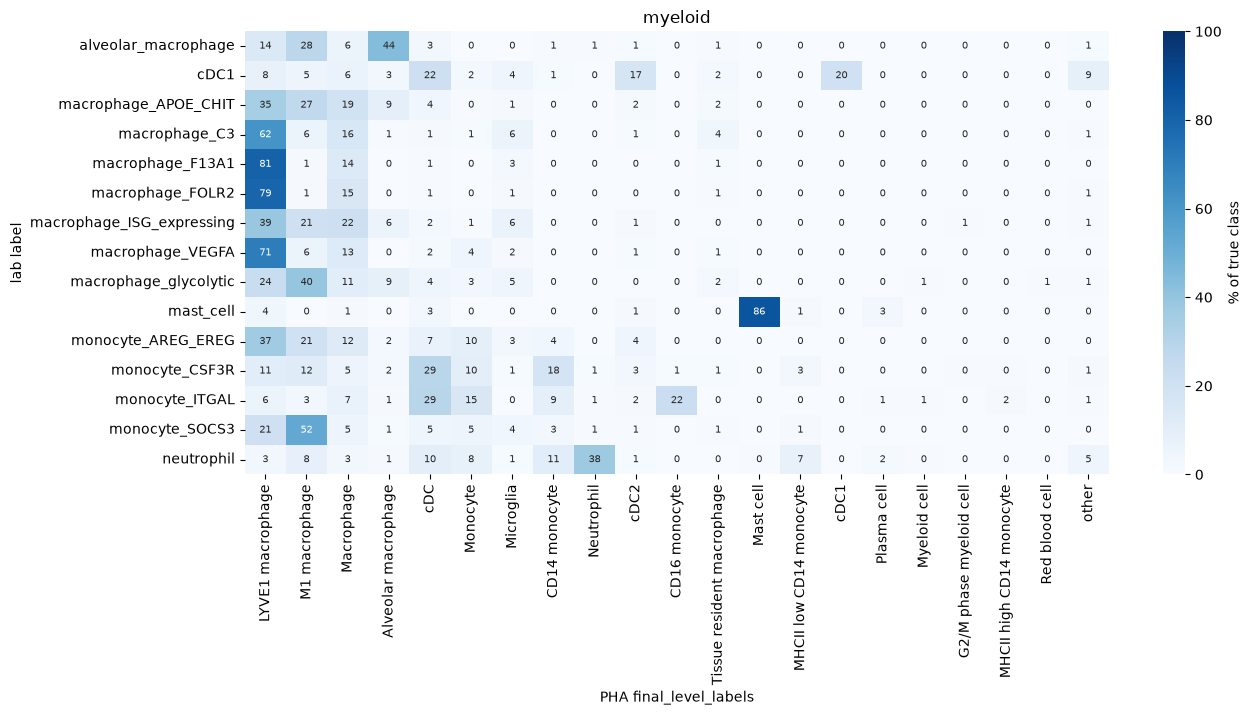

In [7]:
def plot_confusion(name, max_cols=20):
    df = cells[cells["dataset"] == name]
    keep = df["pha_label"].value_counts().head(max_cols).index
    pred = df["pha_label"].where(df["pha_label"].isin(keep), "other")
    ct = pd.crosstab(df["true_label"], pred, normalize="index") * 100
    ct = ct[[c for c in keep if c in ct.columns] + (["other"] if "other" in ct.columns else [])]
    fig, ax = plt.subplots(figsize=(0.45 * ct.shape[1] + 4, 0.35 * ct.shape[0] + 2))
    sns.heatmap(ct, cmap="Blues", vmin=0, vmax=100, annot=ct.round(0), fmt="g",
                annot_kws={"size": 7}, cbar_kws={"label": "% of true class"}, ax=ax)
    ax.set_xlabel("PHA final_level_labels"); ax.set_ylabel("lab label"); ax.set_title(name)
    plt.tight_layout(); plt.savefig(EVAL_DIR / f"confusion_{name}.png", dpi=150); plt.show()

for name in DATASETS:
    plot_confusion(name)

## 5. Confidence vs correctness
Does PHA's calibrated confidence separate correct from wrong calls on our data?

In [8]:
bins = [0, 0.5, 0.75, 0.9, 0.95, 1.0]
calib = (scored.assign(conf_bin=pd.cut(scored["pha_conf"], bins, include_lowest=True))
         .groupby("conf_bin", observed=True)
         .agg(n=("correct", "size"), correct_pct=("correct", lambda s: 100 * s.mean()))
         .round(1))
calib

,n,correct_pct
conf_bin,,
"(-0.001, 0.5]",2101,47.9
"(0.5, 0.75]",3824,55.6
"(0.75, 0.9]",3013,63.8
"(0.9, 0.95]",1848,70.1
"(0.95, 1.0]",12350,84.7


In [9]:
for thr in [0.0, 0.75, 0.9]:
    sub = scored[scored["pha_conf"] >= thr]
    print(f"conf >= {thr:.2f}: keeps {100 * len(sub) / len(scored):5.1f}% of cells | "
          f"correct {100 * sub['correct'].mean():5.1f}% | exact {100 * (sub['outcome'] == 'exact').mean():5.1f}%")

conf >= 0.00: keeps 100.0% of cells | correct  72.7% | exact  43.3%
conf >= 0.75: keeps  74.4% of cells | correct  79.5% | exact  50.5%
conf >= 0.90: keeps  61.4% of cells | correct  82.8% | exact  54.1%


## 6. Glioma malignant states (not scored)
What PHA calls tumour cells, given it was trained only on healthy tissue.

In [10]:
malignant = cells[~cells["scorable"]]
(malignant.groupby("true_label")["pha_label"].apply(lambda s: top_preds(s, k=5))
 .to_frame("top PHA predictions"))

,top PHA predictions
true_label,
AC-like,"Ciliary body cell (34%), Glial cell (26%), Fibrous astrocyte (11%), Astrocyte (7%), Gl..."
MES-like,"Ciliary body cell (48%), Glial cell (12%), Fibrous astrocyte (6%), Astrocyte (6%), Neu..."
NPC-like,"Neuron (50%), Amacrine cell (20%), Neuron of retina (13%), Ganglion cell (7%), Glial c..."
OPC-like,"Glial cell (30%), Oligodendrocyte progenitor cell (24%), Glial cell of brain (12%), Ci..."
